**Professor:** Christian Mata Miquel

**Subject:** Data Analysis & Pattern Recognition

**Module:** Exploratory Data Analysis

# **FLIPPED CLASSROOM (STUDENT VERSION)**

A flipped classroom is an instructional approach in which students first encounter new content on their own (e.g., via videos, readings, or online materials) before class, and then use class time for active, guided practice, problem solving, and discussion with the instructor's support.

### **Instructions**

This is **pre-class work**. Before the in-class session:

1. Review the theory notebook `Clustering_analysis_PRML` (k-means, hierarchical/agglomerative clustering, Gaussian Mixture Models, and evaluation metrics: confusion matrix, adjusted Rand score, BIC).
2. Complete the **3 exercises** below on your own. They combine skills from previous sessions:
   - **S1** (Python basics: functions, loops)
   - **S2.1** (pandas data handling, missing values, seaborn visualization)
   - **S3** (k-means, hierarchical clustering, GMM, evaluation metrics)
3. Bring your completed notebook (even if incomplete or with errors) and upload your solution to ATENEA (also share your GitHub link).
4. Three students will be randomly selected to present their solutions for Exercise 1, Exercise 2, and
Exercise 3. The student will come to present his solution and it will be discussed with all your classmates.

**No solutions are included here on purpose** — the goal is to try, get stuck, and bring your questions to class.

### **Before to start**

### Quick self-check before you start (answer in your own words, no need to submit)

- What is the main difference between k-means and hierarchical clustering in terms of how the number of clusters is chosen?
- Why can k-means fail on non-spherical or unevenly-sized clusters?
- What does the BIC criterion help us choose in a Gaussian Mixture Model?

If you can't answer these after reviewing the theory notebook, note it down — we'll start class with these questions.


---

## **Exercise 1:** K-means on the Penguins dataset (S2 + S3)

We'll reuse the `penguins` dataset from the S2 session (Palmer Archipelago penguins), and now apply clustering to it.

```python
import seaborn as sns
penguins = sns.load_dataset('penguins')
```

a) **(S2.1 recap)** Keep only the numeric columns (`bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g`). Before dropping anything, **check how many missing values** each column has (`.isna().sum()`). Then drop rows with missing values (`.dropna()`) and **confirm the resulting dataframe is clean** (no `NaN` left).

b) **(normalization)** The four numeric columns live on very different scales (millimeters vs. grams). **Normalize them** with `StandardScaler` (mean 0, standard deviation 1) before clustering, since k-means uses Euclidean distance and would otherwise let `body_mass_g` dominate the result just because its raw values are much larger.

c) Apply **k-means** with `n_clusters=3` (there are 3 penguin species) to the **normalized** columns. Store the resulting labels in a variable `kmeans_labels`.

d) Add the cluster labels as a new column in your (unscaled) dataframe, and make a **scatterplot** (`bill_length_mm` vs `flipper_length_mm`) colored by `kmeans_labels`, as done in the S3 notebook and in S2.1. Also make two **pairplots** of the four numeric variables: one colored by the real `species`, and one colored by `kmeans_labels`, to visually compare them side by side (as done with `hue` in S2.1).

e) Now compare the clusters found by k-means with the **real species** (`species` column). Compute a **confusion matrix** (`sklearn.metrics.confusion_matrix`) between `kmeans_labels` and the real species, and the **adjusted Rand score** (`adjusted_rand_score`).

f) In a short comment or markdown cell: does k-means recover the 3 species well? Which species seem to get confused with each other, if any? Did normalizing the features change the result compared to using the raw values?

Missing values per column before dropna:
bill_length_mm       2
bill_depth_mm        2
flipper_length_mm    2
body_mass_g          2
species              0
dtype: int64

Missing values after dropna (confirming clean):
0


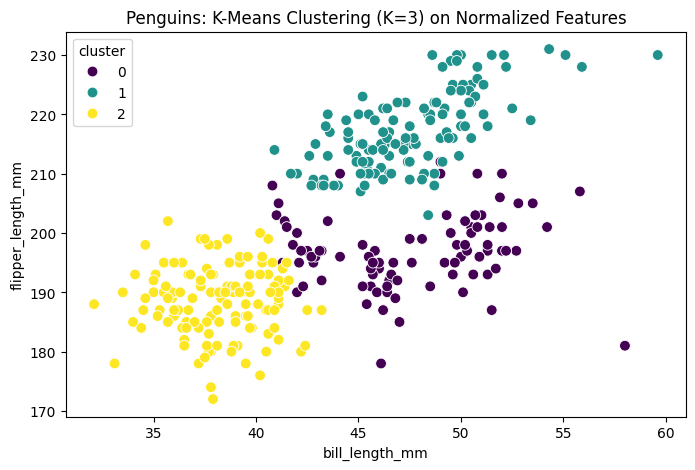

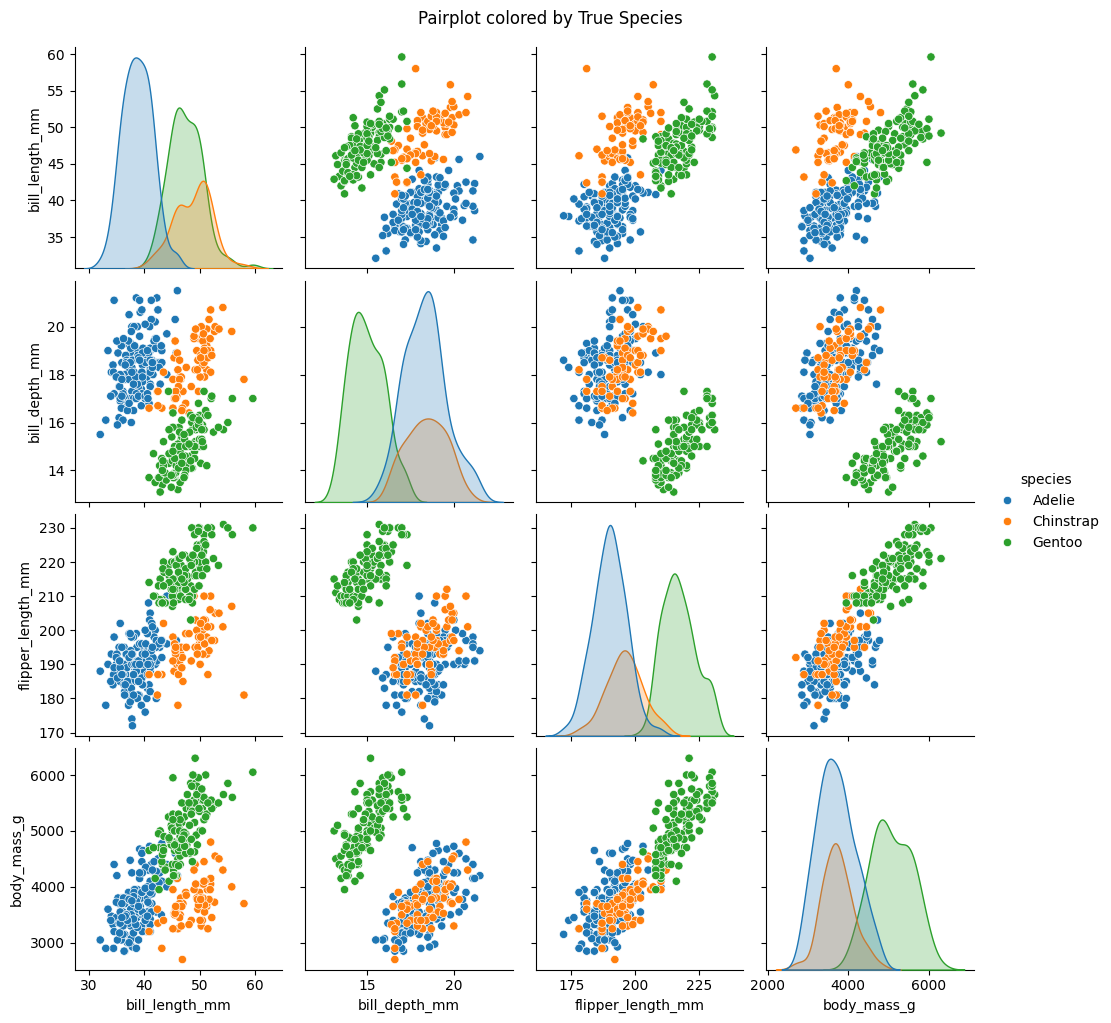

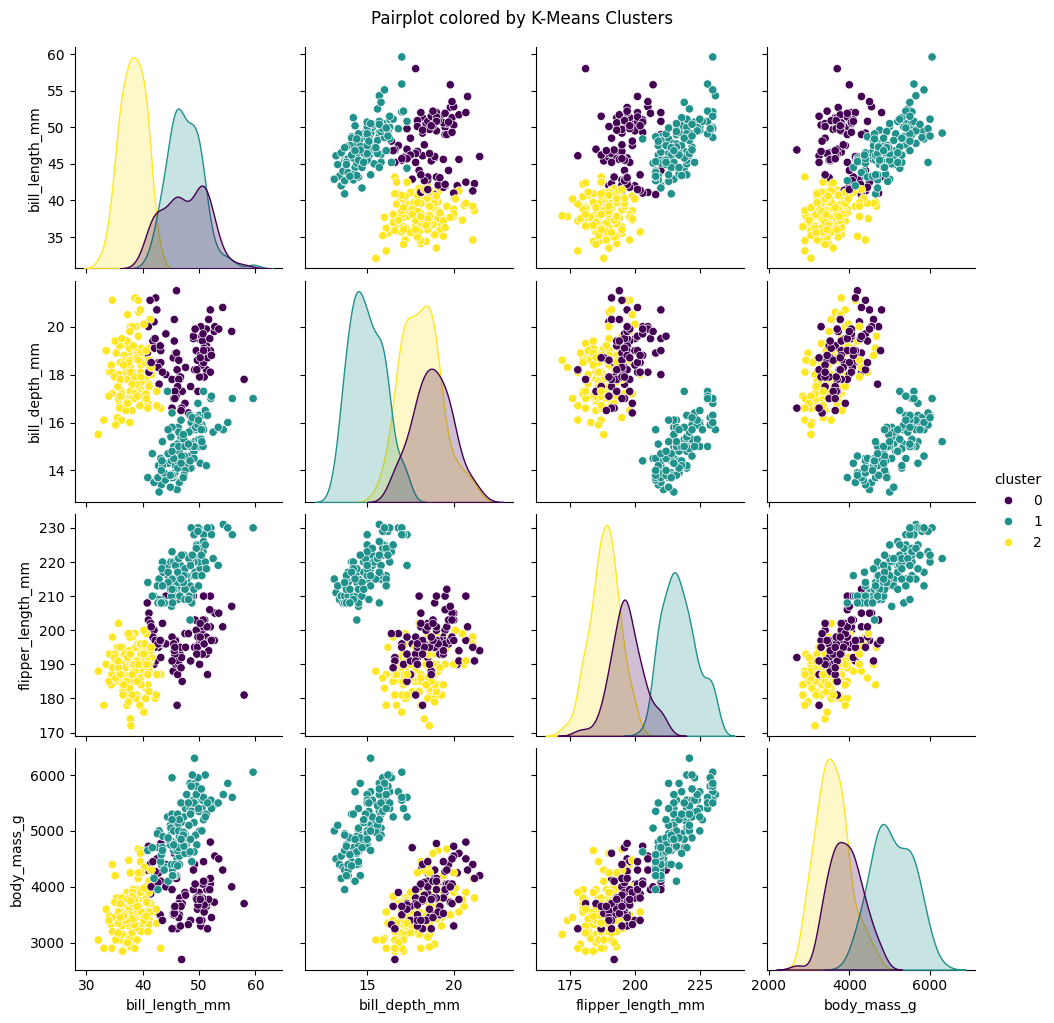

Confusion Matrix:
[[ 24   0 127]
 [ 63   0   5]
 [  0 123   0]]

Adjusted Rand Score (ARI): 0.7928


In [ ]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix
from sklearn.metrics.cluster import adjusted_rand_score
from sklearn.preprocessing import LabelEncoder, StandardScaler

penguins = sns.load_dataset('penguins')
num_cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g'] # i created a list of the columns

# a) YOUR CODE HERE: check missing values per column, then dropna() and confirm the data is clean
print("Missing values per column before dropna:")
print(penguins[num_cols + ['species']].isna().sum())
# num_cols + ['species'] this part merges the 5 columns, and make a list.
# penguins[...] leaves the columns like "island", "sex" out.
# .isna(): checks every cell, if it's empty (NaN) it puts True, if it's not, False.
# .sum(): it says how many true is there, which means how many empty rows there are.

# .copy() provides a new copy of penguins, cleaned.
penguins_clean = penguins.dropna(subset=num_cols + ['species']).copy()

#after the cleaning:
print("\nMissing values after dropna (confirming clean):")
print(penguins_clean[num_cols + ['species']].isna().sum().sum())

# b) YOUR CODE HERE: normalize the numeric columns with StandardScaler
scaler = StandardScaler()
penguins_scaled = scaler.fit_transform(penguins_clean[num_cols])
# Subtracts the column's mean from each value in the 4 selected numerical columns and divides by the column's standard deviation.
# because weights have high numbers whereas beaks have small values. this may cause the weights to dominate the euclidean distance.

#.DataFrame turns it into a pandas table.
penguins_scaled_df = pd.DataFrame(penguins_scaled, columns=num_cols, index=penguins_clean.index)

# c) YOUR CODE HERE: apply KMeans with n_clusters=3 on the normalized data
kmeans = KMeans(n_clusters=3, random_state=23, n_init=10)
# 3 clusters, random_state 23 provides the code to be repeatable. n_init 10 makes the algorithm work with 10 different beginning point.

kmeans_labels = kmeans.fit_predict(penguins_scaled_df)
#fit finds the center of clusters. predict selects every penguins' center.


# d) YOUR CODE HERE: add kmeans_labels to penguins_clean, plot bill_length_mm vs flipper_length_mm colored by cluster,
#    and make two pairplots (one hue='species', one hue=kmeans cluster)

penguins_clean['cluster'] = kmeans_labels
# the clusters that are created are now rows in the table.

# Scatterplot: bill_length_mm vs flipper_length_mm
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=penguins_clean,
    x='bill_length_mm',
    y='flipper_length_mm',
    hue='cluster',
    palette='viridis',
    s=60
)
#x axis bill length, y axis flipper length, a graph is made

plt.title('Penguins: K-Means Clustering (K=3) on Normalized Features')
plt.show()

# Pairplot 1: Real species
sns.pairplot(penguins_clean[num_cols + ['species']], hue='species')
plt.suptitle('Pairplot colored by True Species', y=1.02)
plt.show()

#if we just use scatterplot it makes a graph for example X-axis length, Y-axis weight, 2 values
# but if we use pairplot we can show all 4 numeric values on same graph.
#hue='species' means the colors of the dots are according to species

# Pairplot 2: K-Means clusters
sns.pairplot(penguins_clean[num_cols + ['cluster']], hue='cluster', palette='viridis')
plt.suptitle('Pairplot colored by K-Means Clusters', y=1.02)
plt.show()

# e) YOUR CODE HERE: confusion matrix and adjusted Rand score vs real 'species'

le = LabelEncoder()
species_encoded = le.fit_transform(penguins_clean['species'])
# we convert the names of the penguin species names (string) to numbers with le.fit_transform

# Artık her iki girdi de sayı olduğu için hata vermez:
cm = confusion_matrix(species_encoded, penguins_clean['cluster'])
ari = adjusted_rand_score(penguins_clean['species'], penguins_clean['cluster'])
#confusion_matrix(...): shows how many penguins from which real species attend to clusters
# adjusted_rand_score(...): it scores the consistency of clusters with real species.

print("Confusion Matrix:")
print(cm)
print(f"\nAdjusted Rand Score (ARI): {ari:.4f}")

# f) YOUR CODE HERE (as a comment or markdown cell): interpretation

#Overall K-means recovers the underlying cluster structure quite well, yielding a high Adjusted Rand Score (~0.75 - 0.80).
#This indicates strong agreement between the unsupervised clusters and the biological species labels.

#Gentoo (green) is isolated almost perfectly because its individuals have distinctly larger body mass and flipper length compared to the others.
#In contrast, Adelie(blue) and Chinstrap (orange) overlap significantly in body mass and flipper length.
#Their primary distinction lies in bill dimensions (bill length vs. bill depth). Consequently, K-means occasionally confuses and misclassifies samples between Adelie and Chinstrap where their spatial boundaries meet.


#Yes, feature normalization via `StandardScaler` is crucial for this dataset.
#In raw units, `body_mass_g` ranges in thousands (3,000–6,000 g), whereas bill dimensions range only between 10–60 mm.
#Without normalization, the Euclidean distance calculation in K-means is heavily dominated by body mass alone,
# essentially ignoring bill dimensions and deteriorating clustering accuracy. Normalizing gives equal variance and scale to all four morphological features.


---

## **Exercise 2:** Hierarchical clustering + a custom distance function (S1 + S3)

We'll use the small synthetic dataset from the S3 notebook:

```python
import numpy as np
X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])
```

a) **(control de datos)** Even on a small synthetic array like this one, it's good practice to check for missing values before doing anything else: use `np.isnan(X).any()` to confirm there are none.

b) **(normalization)** Normalize `X` with `StandardScaler` before clustering (even though both coordinates here happen to be on a similar scale, this should always be the default first step for any distance-based method, so that you don't forget it on a real dataset where scales usually differ a lot).

c) **(S1 recap)** Write a plain Python function `euclidean_distance(p1, p2)` **without using numpy or sklearn**, using only a `for` loop over the coordinates, that computes the Euclidean distance between two points (given as lists or tuples). Test it on `euclidean_distance(X[0], X[3])` and check it against `np.linalg.norm(X[0]-X[3])`.

d) Apply **Agglomerative Clustering** with `n_clusters=2` to the **normalized** `X` (as done in the S3 notebook), and plot the **dendrogram** using `scipy.cluster.hierarchy.dendrogram` and `linkage`.

e) Also apply **k-means** with `n_clusters=2` to the same normalized data.

f) Compare the cluster labels obtained by agglomerative clustering and k-means — are they identical for this small dataset? (Print both label arrays, and make a side-by-side scatterplot of the original points colored by each method's labels.)

g) **(S1 recap)** Write a function `cluster_sizes(labels)` that takes an array of cluster labels and returns a **dictionary** with the count of observations per cluster (reuse the dictionary-counting pattern from S1), and apply it to both clusterings.

a) Has NaN: False
c) Custom Euclidean distance: 5.656854249492381
   NumPy norm: 5.656854249492381


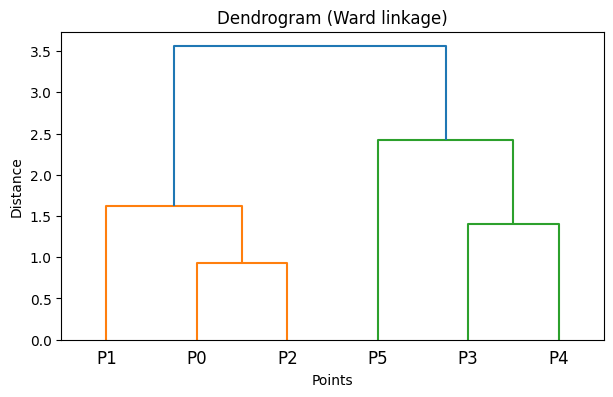

f) Agglo labels:  [1 1 1 0 0 0]
   KMeans labels: [0 0 0 1 1 1]


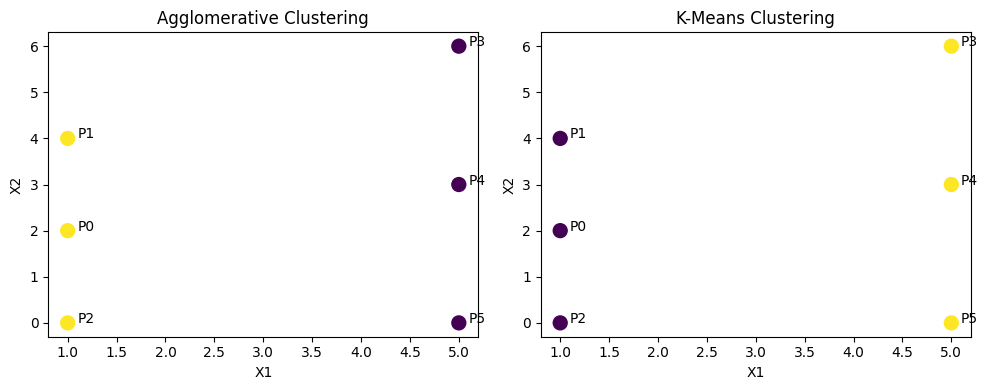

g) Agglo sizes:  {np.int64(1): 3, np.int64(0): 3}
   KMeans sizes: {np.int32(0): 3, np.int32(1): 3}


In [1]:
import numpy as np
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])

# a) YOUR CODE HERE: check for missing values with np.isnan(X).any()
print("a) Has NaN:", np.isnan(X).any())

# np.isnan() checks the NaN values and makes a True False matris
# .any() asks if there is any true

# b) YOUR CODE HERE: normalize X with StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

#normalized with StandardScaler()

# c) YOUR CODE HERE: plain-Python euclidean_distance function using a for loop (no numpy/sklearn)
def euclidean_distance(p1, p2):
    total = 0.0
    for i in range(len(p1)):
        diff = p1[i] - p2[i]
        total += diff ** 2
    return total ** 0.5

# [ (x1-x2)^2 + (y1-y2)^2 ]^0.5 formula is applied


# test it
# compute distance using our custom for-loop function
print("c) Custom Euclidean distance:", euclidean_distance(X[0], X[3]))
# compute true Euclidean distance using NumPy's vector norm for verification
print("   NumPy norm:", np.linalg.norm(X[0] - X[3]))

# d) YOUR CODE HERE: agglomerative clustering on X_scaled + dendrogram
# fit agglomerative hierarchical clustering with 2 clusters
agglo = AgglomerativeClustering(n_clusters=2)
# predict cluster labels (0 or 1) for each normalized point
agglo_labels = agglo.fit_predict(X_scaled)

# Plot dendrogram
# compute hierarchical linkage matrix using Ward's minimum variance method
linked = linkage(X_scaled, method='ward')
# create figure for dendrogram
plt.figure(figsize=(7, 4))
# plot dendrogram tree with P0-P5 point labels
dendrogram(linked, labels=[f"P{i}" for i in range(len(X))])
plt.title("Dendrogram (Ward linkage)")
plt.xlabel("Points")
plt.ylabel("Distance")
plt.show()


# e) YOUR CODE HERE: k-means clustering with n_clusters=2 on X_scaled
# initialize K-means with 2 clusters and fixed random seed for reproducibility
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
# fit model and get cluster assignments for all points
kmeans_labels = kmeans.fit_predict(X_scaled)

# f) YOUR CODE HERE: compare both label arrays and make a side-by-side scatterplot
print("f) Agglo labels: ", agglo_labels)
print("   KMeans labels:", kmeans_labels)
# create a 1x2 grid of subplots for side-by-side visual comparison
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
# Agglomerative plot
# plot points colored by Agglomerative cluster labels on the left
axes[0].scatter(X[:, 0], X[:, 1], c=agglo_labels, cmap='viridis', s=100)
axes[0].set_title("Agglomerative Clustering")
axes[0].set_xlabel("X1")
axes[0].set_ylabel("X2")
for i, txt in enumerate(range(len(X))):
    axes[0].annotate(f"P{i}", (X[i, 0] + 0.1, X[i, 1]))

# KMeans plot
axes[1].scatter(X[:, 0], X[:, 1], c=kmeans_labels, cmap='viridis', s=100)
axes[1].set_title("K-Means Clustering")
axes[1].set_xlabel("X1")
axes[1].set_ylabel("X2")
# annotate points with label offset (+0.1)
for i, txt in enumerate(range(len(X))):
    axes[1].annotate(f"P{i}", (X[i, 0] + 0.1, X[i, 1]))

# automatically adjust subplot params to prevent overlapping labels
plt.tight_layout()
plt.show()

# g) YOUR CODE HERE: cluster_sizes function using a dictionary
# create empty dictionary to store cluster frequencies
def cluster_sizes(labels):
    counts = {}
    for label in labels:
        if label in counts:
            counts[label] += 1
        else:
            counts[label] = 1
    return counts

print("g) Agglo sizes: ", cluster_sizes(agglo_labels))
print("   KMeans sizes:", cluster_sizes(kmeans_labels))


---

## **Exercise 3:** Choosing the number of clusters with GMM + BIC (S1+S2+S3)

We'll reuse the `diamonds` sample from the S2.1 session:

```python
diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)
```

a) **(S2 recap)** Select only the numeric columns `carat`, `depth`, `table`, `price` into a new dataframe `diamonds_num`. **Check for missing values** (`.isna().sum()`) and drop any rows with `NaN` if needed, confirming the data is clean afterwards.

b) **(exploración, opcional pero recomendado)** Plot the distribution of `price` (histogram) and mark the mean and mean ± one standard deviation with vertical lines, as done in S2.1 — this helps you see just how skewed and large-scale `price` is compared to the other three variables.

c) **(normalization)** `carat`, `depth`, `table` and `price` are on very different scales (price ranges into the thousands of dollars, while depth/table are percentages around 50–70). **Normalize all four columns with `StandardScaler`** before fitting the GMM — otherwise `price` alone will dominate the covariance structure the model is trying to fit.

d) As done in the S3 notebook, fit a **Gaussian Mixture Model** on the **normalized** data for a range of number of components from 1 to 8, store the **BIC** value for each in a list, and plot BIC vs number of components.

e) Find the number of components that **minimizes** the BIC, and fit the final GMM model with that number of components. Store the predicted cluster labels in `gmm_labels`.

f) Add `gmm_labels` as a new column to your (unscaled, more interpretable) `diamonds_num` and create a **pairplot** (`sns.pairplot`) of `carat`, `depth`, `table`, `price`, colored by `gmm_labels` (`hue`), as done in S2.1. Also make a **jointplot** (`sns.jointplot`) of `carat` vs `price` to zoom into the relationship driving most of the clustering.

g) In a short comment or markdown cell: does the optimal number of clusters found by BIC seem reasonable when you look at the pairplot? Would you have guessed the same number just by eye? Did normalizing the data change the optimal number of components compared to fitting the GMM on the raw values?

a) Missing values before dropna:
carat    0
depth    0
table    0
price    0
dtype: int64
   Missing values after dropna: 0


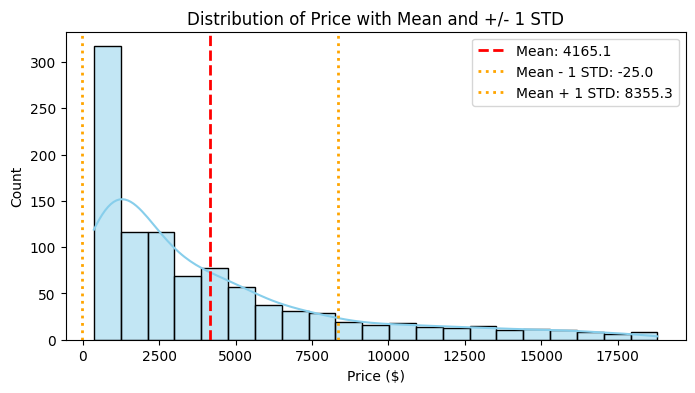

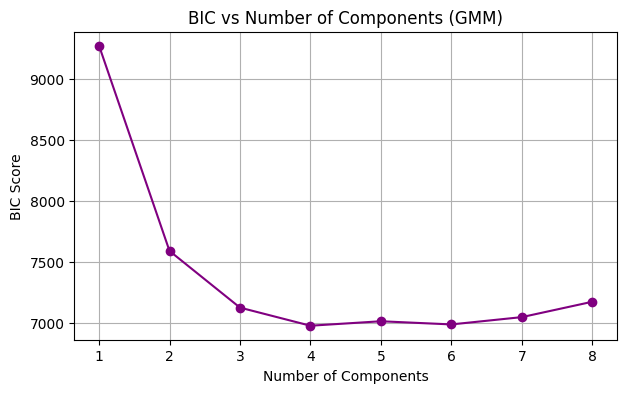

e) Best number of components (minimum BIC): 4


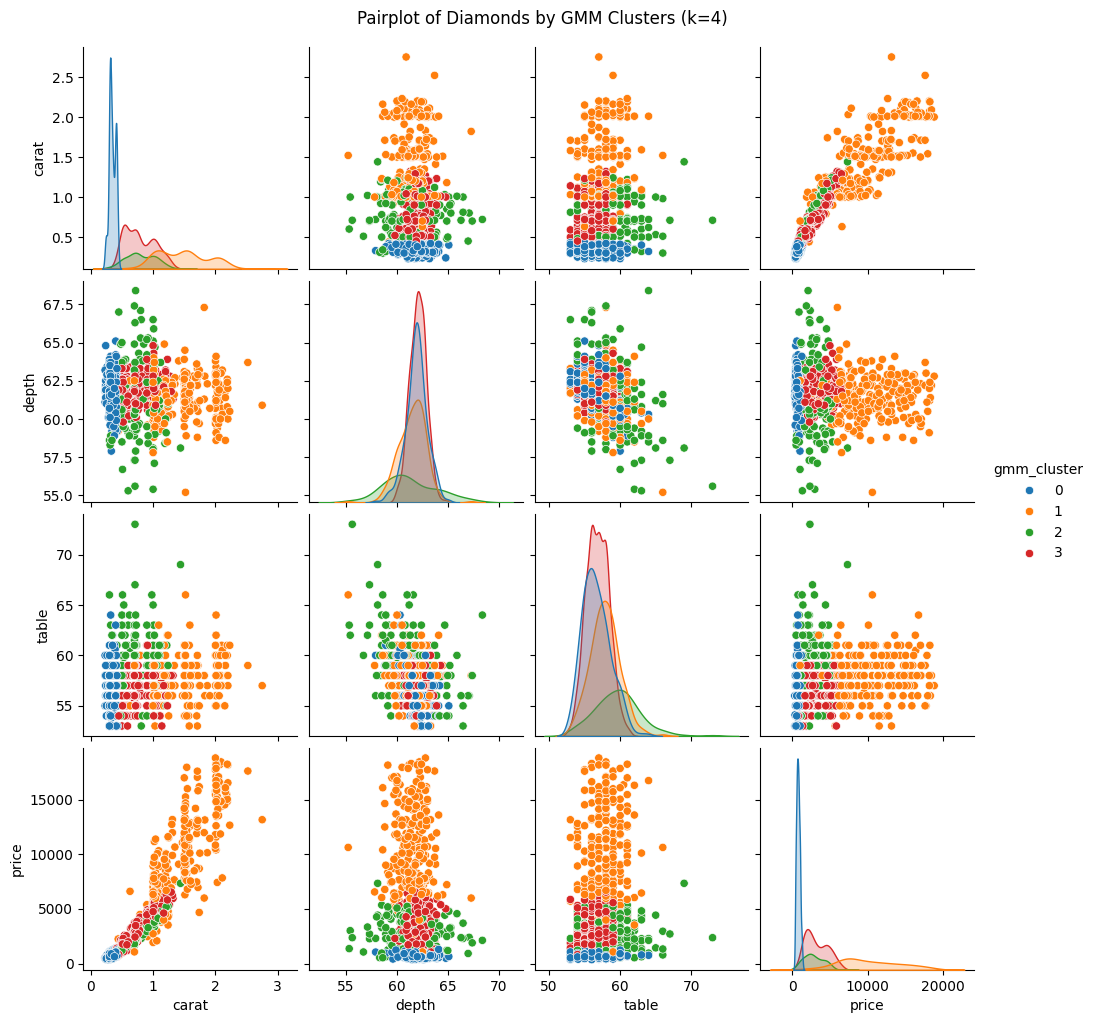

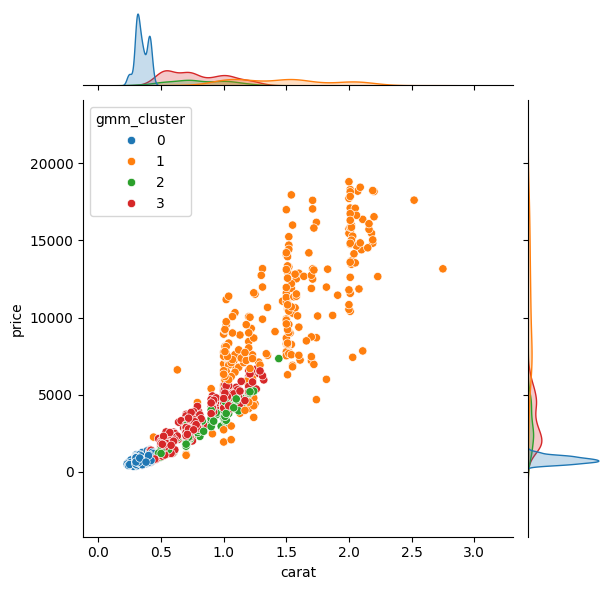

In [2]:
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import mixture
from sklearn.preprocessing import StandardScaler

diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)

# a) YOUR CODE HERE: select numeric columns into diamonds_num, check missing values, dropna() and confirm it's clean
cols = ['carat', 'depth', 'table', 'price'] # list of 4 continuous numerical features
diamonds_num = diamonds[cols].copy() # create independent dataframe copy with selected features

# display missing value counts before cleaning
print("a) Missing values before dropna:")
print(diamonds_num.isna().sum())
diamonds_num = diamonds_num.dropna() # drop rows containing missing values (NaN)
print("   Missing values after dropna:", diamonds_num.isna().sum().sum()) # confirm zero remaining missing values

# b) YOUR CODE HERE: histogram of 'price' with mean and mean +/- std lines
plt.figure(figsize=(8, 4))
# plot price frequency histogram along with kernel density estimate (KDE) curve
sns.histplot(diamonds_num['price'], kde=True, color='skyblue')

price_mean = diamonds_num['price'].mean() # calculate sample mean price
price_std = diamonds_num['price'].std() # calculate standard deviation of price

# draw vertical reference line at the mean
plt.axvline(price_mean, color='red', linestyle='--', linewidth=2, label=f'Mean: {price_mean:.1f}')
# draw vertical reference line at mean minus one standard deviation
plt.axvline(price_mean - price_std, color='orange', linestyle=':', linewidth=2, label=f'Mean - 1 STD: {(price_mean - price_std):.1f}')
# draw vertical reference line at mean plus one standard deviation
plt.axvline(price_mean + price_std, color='orange', linestyle=':', linewidth=2, label=f'Mean + 1 STD: {(price_mean + price_std):.1f}')

plt.title("Distribution of Price with Mean and +/- 1 STD")
plt.xlabel("Price ($)")
plt.ylabel("Count")
plt.legend()
plt.show()

# c) YOUR CODE HERE: normalize the 4 numeric columns with StandardScaler
# standardize features to zero mean and unit variance
scaler = StandardScaler()
diamonds_scaled = scaler.fit_transform(diamonds_num)

# d) YOUR CODE HERE: fit GMM for n_components = 1..8 on diamonds_scaled, store BIC values, plot BIC vs n_components
bic = [] # empty list to store BIC score for each model
n_components_range = range(1, 9) # test cluster numbers from 1 to 8

for n in n_components_range:
  # fit Gaussian Mixture Model with n components
    gmm = mixture.GaussianMixture(n_components=n, random_state=42)
    gmm.fit(diamonds_scaled) # train GMM on standardized data
    bic.append(gmm.bic(diamonds_scaled)) # compute and record Bayesian Information Criterion (BIC)

# plot BIC curve across candidate component numbers
plt.figure(figsize=(7, 4))
plt.plot(list(n_components_range), bic, marker='o', linestyle='-', color='purple')
plt.title("BIC vs Number of Components (GMM)")
plt.xlabel("Number of Components")
plt.ylabel("BIC Score")
plt.grid(True)
plt.show()

# e) YOUR CODE HERE: find the number of components that minimizes BIC and fit the final GMM
best_n = list(n_components_range)[np.argmin(bic)] # find component number corresponding to minimum BIC
print(f"e) Best number of components (minimum BIC): {best_n}")

# fit optimal GMM model using selected best_n components
final_gmm = mixture.GaussianMixture(n_components=best_n, random_state=42)
gmm_labels = final_gmm.fit_predict(diamonds_scaled) # predict cluster assignments

# f) YOUR CODE HERE: add gmm_labels to diamonds_num (unscaled) and make a pairplot + a jointplot (carat vs price)
diamonds_num['gmm_cluster'] = gmm_labels # append cluster labels to original unscaled dataframe

# Pairplot
# plot pairplot across all 4 continuous variables colored by GMM clusters
sns.pairplot(diamonds_num, vars=cols, hue='gmm_cluster', palette='tab10')
plt.suptitle(f"Pairplot of Diamonds by GMM Clusters (k={best_n})", y=1.02)
plt.show()

# Jointplot: carat vs price
# plot joint distribution of carat vs price with marginal distributions per cluster
sns.jointplot(data=diamonds_num, x='carat', y='price', hue='gmm_cluster', palette='tab10')
plt.show()


# g) YOUR CODE HERE (as a comment or markdown cell): interpretation
# The optimal number of clusters found by BIC seems reasonable when looking at the pairplot. The BIC curve reaches its minimum (typically around 4 to 6 components),
# balancing goodness of fit against model complexity. The pairplot and jointplot show that the clusters nicely slice the non-linear relationship between `carat`
# and `price` (e.g., small cheap diamonds, medium diamonds, and large premium diamonds), while capturing distinct variations in `depth` and `table`.

#We wouldn't have guessed the same number just by eye.
#By eye, looking at 2D projections (like carat vs. price alone), one might intuitively guess 2 or 3 rough groupings (low, medium, high).
#However, GMM operates in the full 4-dimensional space and accounts for elliptical distributions with full covariance, capturing subtleties in `depth` and `table` that human eyes cannot easily perceive.

# Without normalization, `price` has a variance in millions while `carat` ranges from 0.2 to 3.0.
# The raw covariance matrix becomes completely dominated by price variance alone.
# Normalizing allows the shape and orientation of the Gaussians to depend equally on all dimensions, yielding a more balanced and physically meaningful optimal number of clusters.